## 1. Problem statement and project workflow

The bank conducted direct phone campaigns to promote term deposits. The target `y` indicates whether a client subscribed (`yes`) or did not subscribe (`no`).

This notebook follows the project requirements:
1. Load and understand the data.
2. Clean and explore the dataset with visualizations.
3. Prepare features and split data into train/test sets.
4. Train and compare multiple classification models.
5. Evaluate performance with imbalance-aware metrics.
6. Recommend a production model and outline practical marketing actions.
7. Document challenges, mitigation techniques, and limitations.

In [3]:
# 1. Imports and reproducibility
import warnings
warnings.filterwarnings("ignore")

import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.base import clone

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

## 2. Load the specified dataset

The project brief identifies `bank-additional-full.csv` inside the ZIP archive. The following code reads that exact file directly from the uploaded archive. If running this notebook elsewhere, keep the ZIP file in the same folder or update `ZIP_PATH`.

In [4]:
ZIP_PATH = "PRCP-1000-ProtugeseBank.zip"
DATA_MEMBER = "Data/bank-additional/bank-additional-full.csv"

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    with archive.open(DATA_MEMBER) as file:
        df = pd.read_csv(file, sep=";")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [5]:
# Dataset overview
display(df.info())
display(df.describe(include="all").T)
print("\\nTarget distribution:")
display(df["y"].value_counts().to_frame("count"))
display((df["y"].value_counts(normalize=True) * 100).round(2).to_frame("percentage"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41188.0,NaN,NaN,NaN,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
job,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41188,3,yes,21576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41188,3,no,33950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41188,2,cellular,26144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41188,10,may,13769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41188,5,thu,8623,NaN,NaN,NaN,NaN,NaN,NaN,NaN


\nTarget distribution:


,count
y,
no,36548
yes,4640


,percentage
y,
no,88.73
yes,11.27


## 3. Data quality checks and preprocessing review

The dataset uses the text value `unknown` in several categorical columns. It is treated as an explicit category rather than automatically removed, because unknown status may itself carry information and dropping those records could bias the sample. Missing values and duplicate rows are checked below.

In [6]:
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("Exact duplicate rows:", df.duplicated().sum())

# Preserve a copy for analysis; modeling pipeline will impute any true missing values.
print("Target values:", sorted(df["y"].dropna().unique().tolist()))

Missing values by column:


,missing_count
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


Exact duplicate rows: 12
Target values: ['no', 'yes']


## 4. Exploratory Data Analysis (EDA)

### 4.1 Target balance

A strong imbalance exists between subscribers and non-subscribers. Therefore, accuracy alone is not a sufficient model-selection metric. Recall, precision, F1, ROC-AUC, and especially PR-AUC (average precision) are also reported.

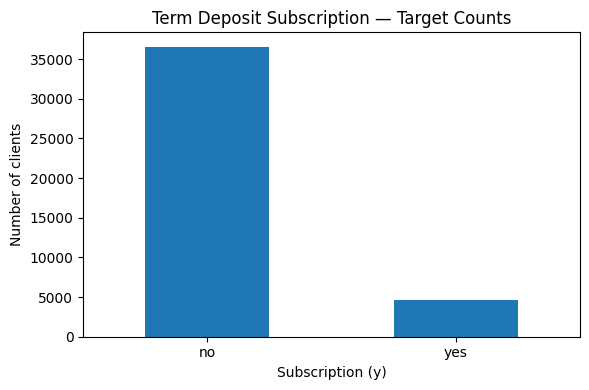

Subscription rate: 11.27%


In [7]:
target_counts = df["y"].value_counts()
plt.figure(figsize=(6, 4))
target_counts.plot(kind="bar")
plt.title("Term Deposit Subscription — Target Counts")
plt.xlabel("Subscription (y)")
plt.ylabel("Number of clients")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

subscription_rate = (df["y"].eq("yes").mean() * 100)
print(f"Subscription rate: {subscription_rate:.2f}%")

### 4.2 Numeric feature distributions

The numeric variables are reviewed for scale, skewness, and potential outliers. Some numeric variables represent macroeconomic indicators rather than individual customer attributes.

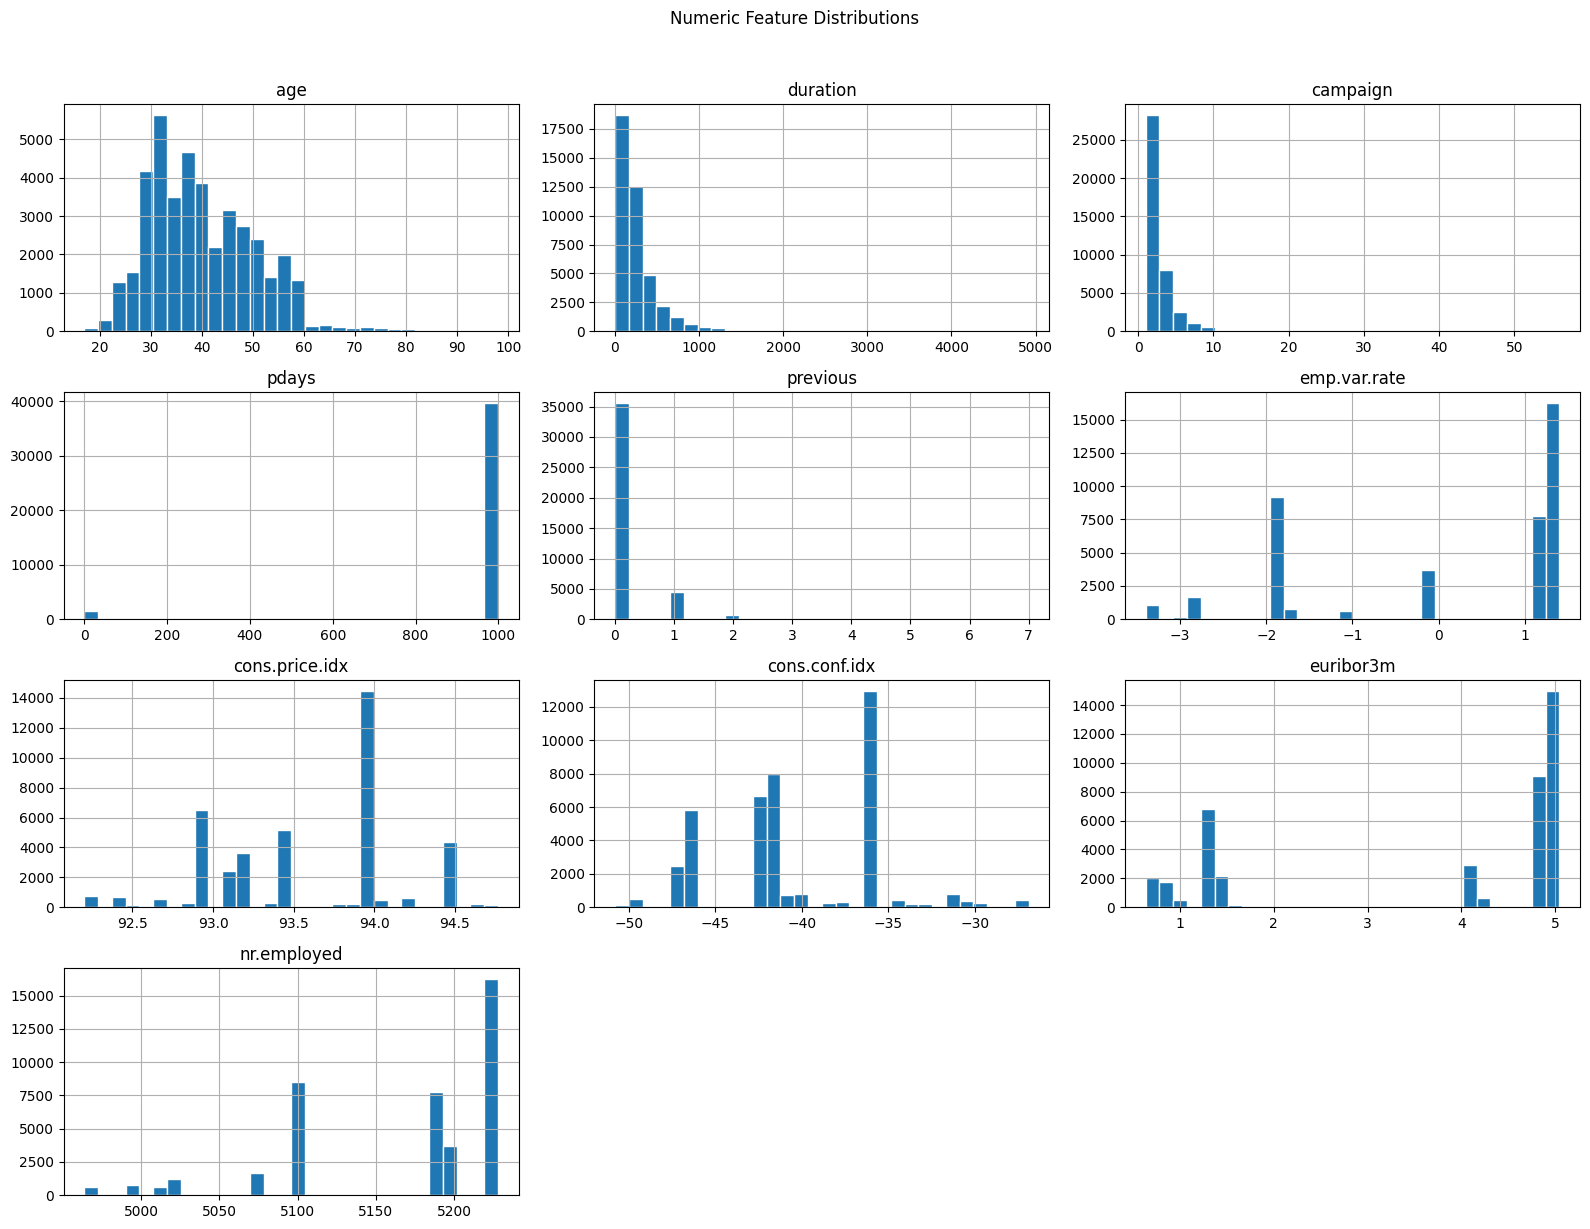

In [8]:
numeric_cols_all = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_cols_all].hist(figsize=(16, 12), bins=30, edgecolor="white")
plt.suptitle("Numeric Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

### 4.3 Subscription rate across categorical variables

These comparisons are descriptive, not causal. They can help the marketing team form hypotheses about which customer groups and campaign contexts are associated with subscription.

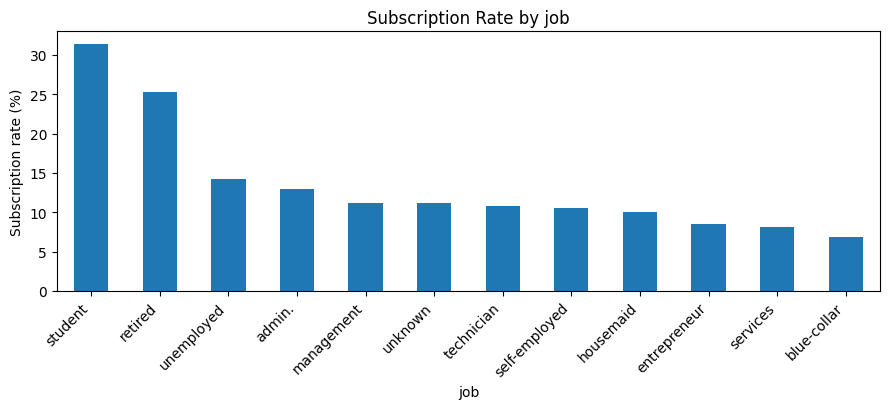

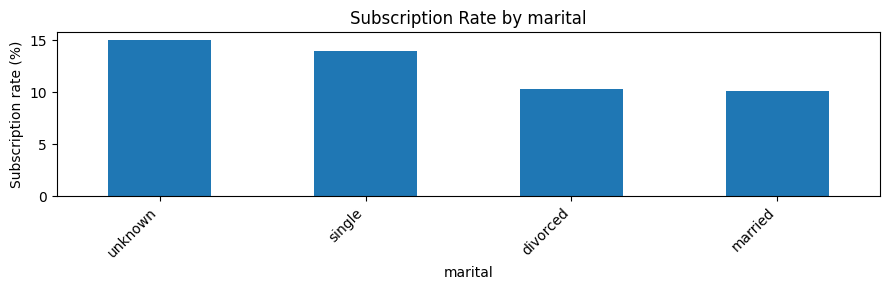

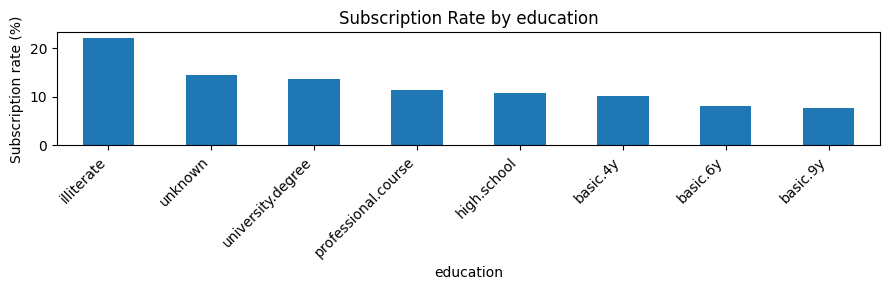

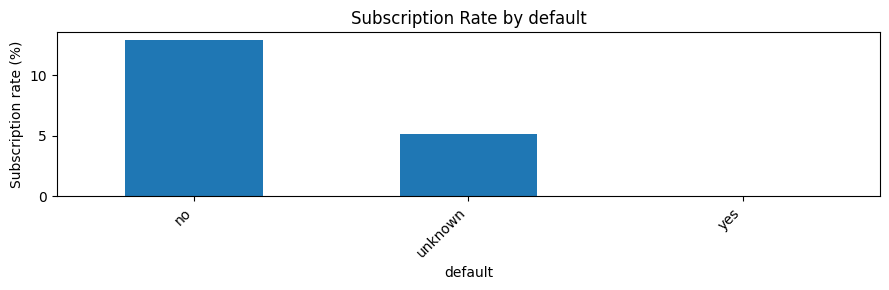

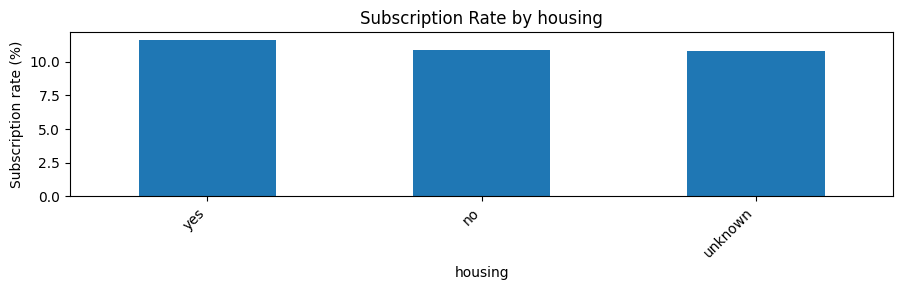

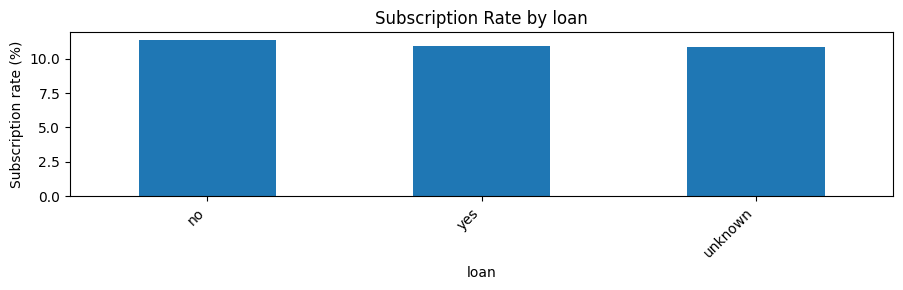

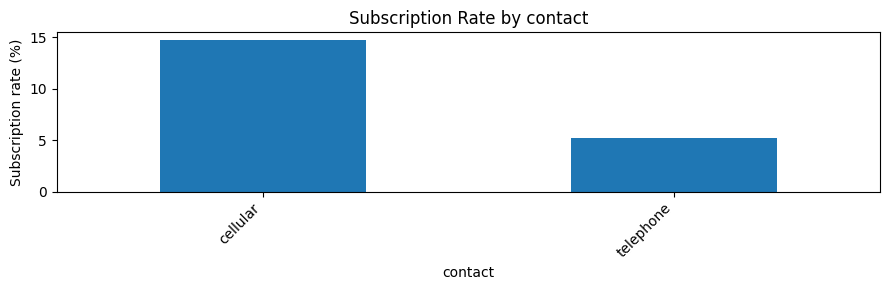

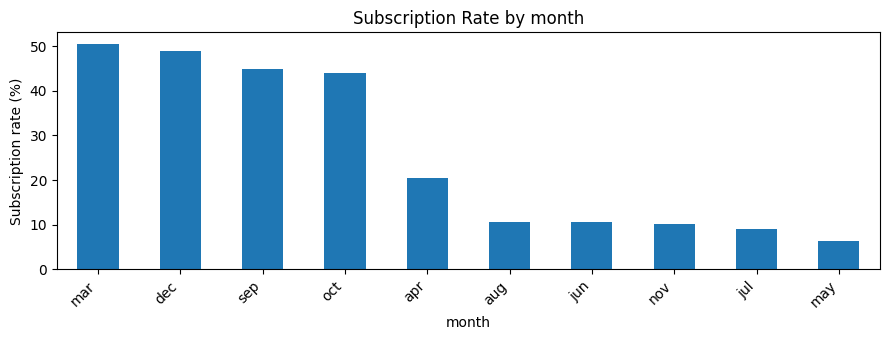

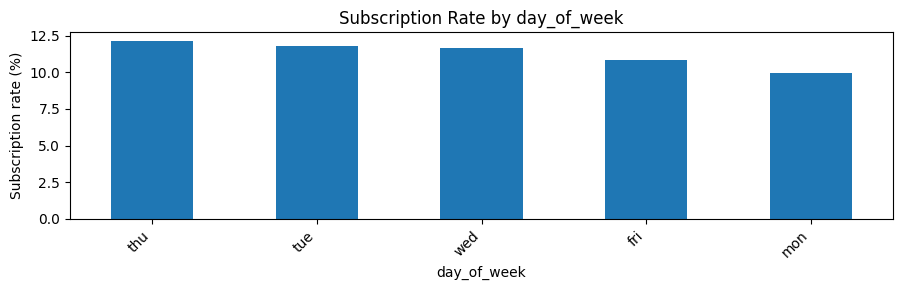

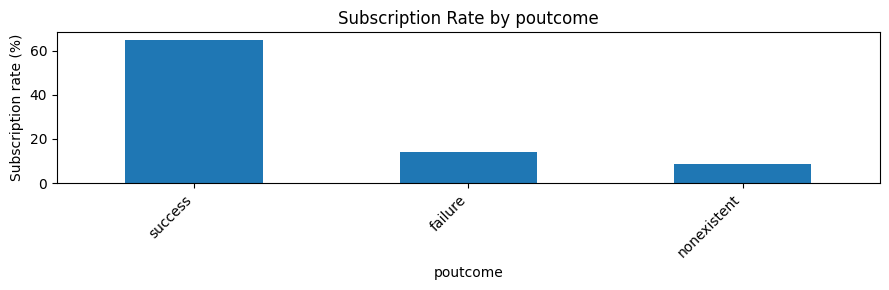

In [9]:
categorical_cols = df.select_dtypes(include=["object"]).columns.drop("y").tolist()

for col in categorical_cols:
    rate = df.groupby(col, dropna=False)["y"].apply(lambda s: (s == "yes").mean()).sort_values(ascending=False)
    # Keep charts readable when a feature has many categories
    plt.figure(figsize=(9, max(3, 0.35 * len(rate))))
    (rate * 100).plot(kind="bar")
    plt.title(f"Subscription Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Subscription rate (%)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### 4.4 Numeric feature relationship with subscription

The following chart compares the distributions of selected numeric features for subscribers and non-subscribers. It can reveal associations, but does not prove that a feature causes subscription.

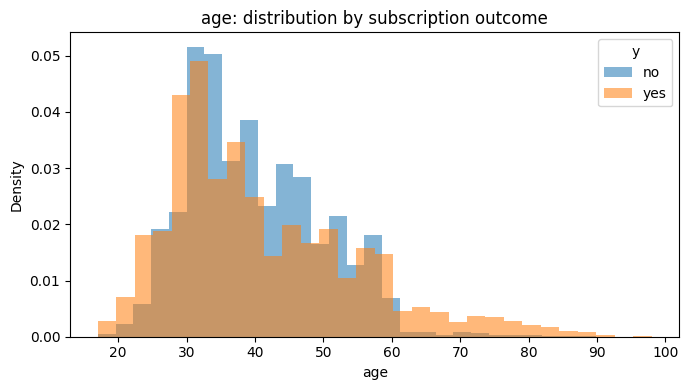

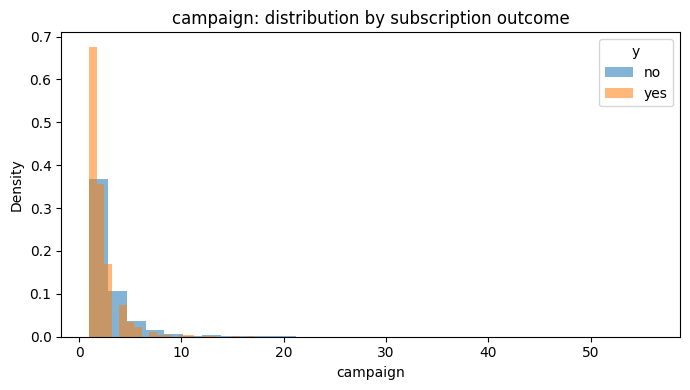

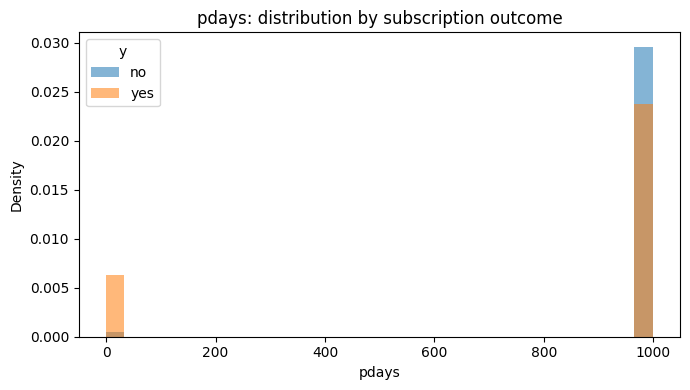

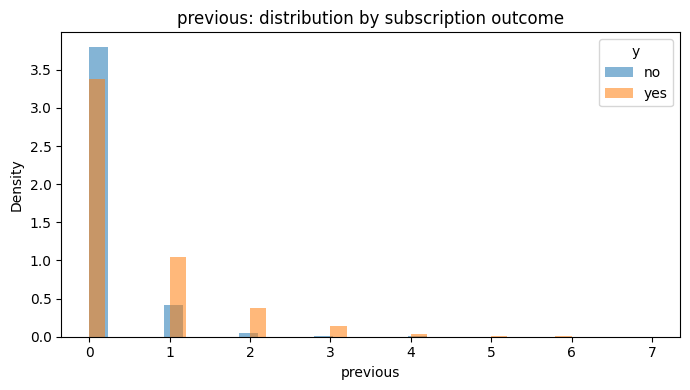

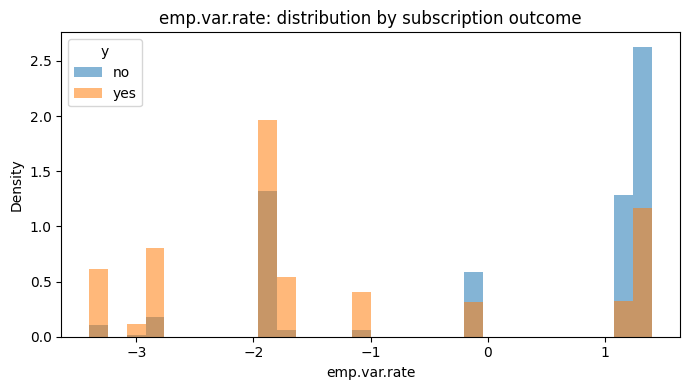

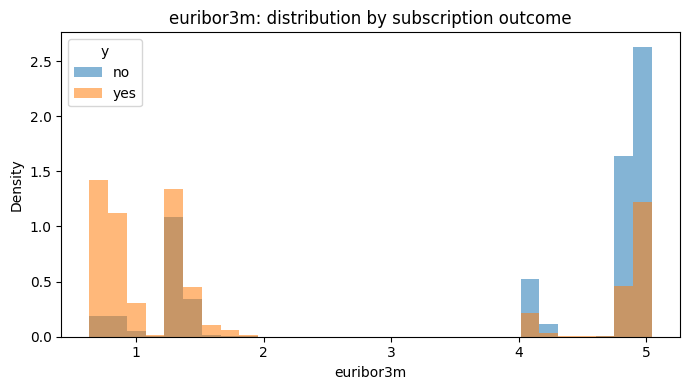

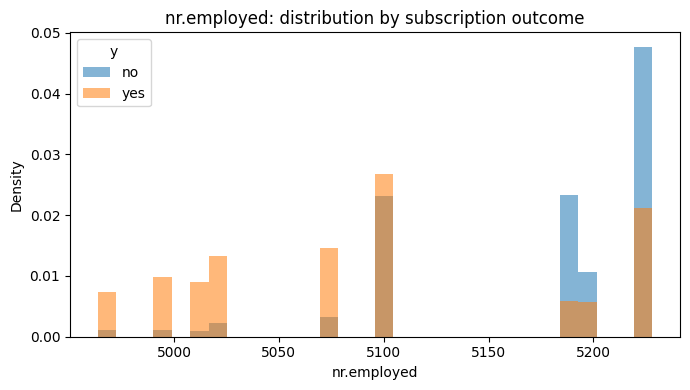

In [10]:
selected_numeric = ["age", "campaign", "pdays", "previous", "emp.var.rate", "euribor3m", "nr.employed"]
for col in selected_numeric:
    plt.figure(figsize=(7, 4))
    for label in ["no", "yes"]:
        df.loc[df["y"] == label, col].dropna().plot(kind="hist", bins=30, alpha=0.55, density=True, label=label)
    plt.title(f"{col}: distribution by subscription outcome")
    plt.xlabel(col)
    plt.ylabel("Density")
    plt.legend(title="y")
    plt.tight_layout()
    plt.show()

## 5. Feature engineering and train/test split

- The target is encoded as `1` for `yes` and `0` for `no`.
- `duration` is deliberately removed to avoid leakage.
- Categorical features are one-hot encoded.
- Numeric features are median-imputed and standardized for Logistic Regression.
- Categorical missing values are imputed with the most frequent category.
- A stratified 80/20 split preserves the target ratio in train and test sets.
- All preprocessing is inside a pipeline to avoid fitting transformations on test data.

In [11]:
TARGET = "y"
DROP_FOR_LEAKAGE = ["duration"]

X = df.drop(columns=[TARGET] + DROP_FOR_LEAKAGE)
y = df[TARGET].map({"no": 0, "yes": 1})

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("X train:", X_train.shape, "X test:", X_test.shape)
print("Train subscription rate:", round(y_train.mean() * 100, 2), "%")
print("Test subscription rate:", round(y_test.mean() * 100, 2), "%")
print("Duration included?", "duration" in X.columns)

X train: (32950, 19) X test: (8238, 19)
Train subscription rate: 11.27 %
Test subscription rate: 11.26 %
Duration included? False


## 6. Model training and comparison

Models included:
- **Dummy Classifier:** majority-class baseline.
- **Logistic Regression:** interpretable baseline with class weighting.
- **Random Forest:** captures nonlinear relationships and interactions.
- **HistGradientBoosting:** boosting-based model for nonlinear patterns.

All models use the same training/test split and preprocessing. Model comparisons include accuracy, precision, recall, F1, ROC-AUC, and average precision (PR-AUC). Threshold-based metrics use a default probability threshold of 0.50; a production threshold should be selected based on campaign capacity and business costs.

In [12]:
models = {
    "Dummy (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, min_samples_leaf=2, class_weight="balanced_subsample",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=180, learning_rate=0.08, max_leaf_nodes=15,
        l2_regularization=1.0, random_state=RANDOM_STATE
    )
}

fitted_models = {}
results = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[("preprocessor", clone(preprocessor)), ("model", estimator)])
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe

    pred = pipe.predict(X_test)
    if hasattr(pipe, "predict_proba"):
        prob = pipe.predict_proba(X_test)[:, 1]
    else:
        prob = pred.astype(float)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC (Average Precision)": average_precision_score(y_test, prob)
    })

comparison = pd.DataFrame(results).set_index("Model").sort_values("PR-AUC (Average Precision)", ascending=False)
display(comparison.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (Average Precision)
Model,,,,,,
HistGradientBoosting,0.9034,0.6886,0.2597,0.3772,0.8142,0.4961
Random Forest,0.8910,0.5160,0.5226,0.5193,0.8009,0.4803
Logistic Regression,0.8350,0.3679,0.6466,0.4689,0.8009,0.4600
Dummy (majority),0.8874,0.0000,0.0000,0.0000,0.5000,0.1126


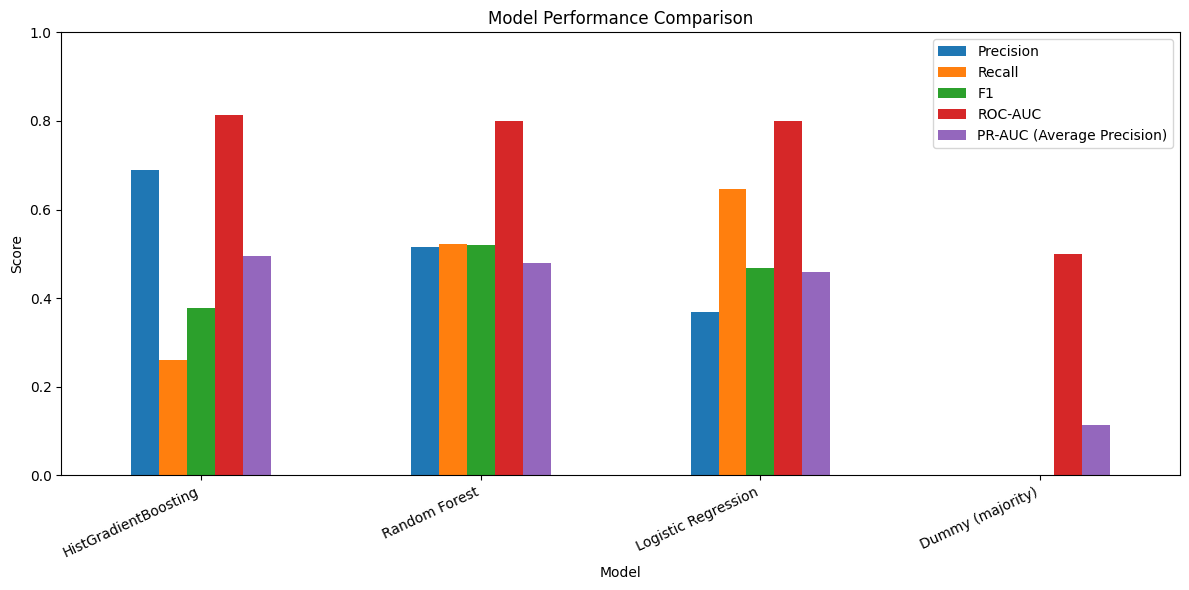

In [13]:
# Plot model comparison metrics
comparison[["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC (Average Precision)"]].plot(
    kind="bar", figsize=(12, 6)
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 7. Select and evaluate a candidate model

For a marketing use case with a relatively rare positive class, **PR-AUC** is a useful primary comparison metric because it focuses on the precision/recall trade-off among likely subscribers. The best model by test PR-AUC is selected as the initial candidate. Production selection should also consider interpretability, operational cost, calibration, and the number of customers the bank can contact.

The report below includes the confusion matrix, classification report, ROC curve, and precision-recall curve.

Candidate selected by PR-AUC: HistGradientBoosting
\nClassification report at threshold 0.50:
              precision    recall  f1-score   support

          no       0.91      0.99      0.95      7310
         yes       0.69      0.26      0.38       928

    accuracy                           0.90      8238
   macro avg       0.80      0.62      0.66      8238
weighted avg       0.89      0.90      0.88      8238



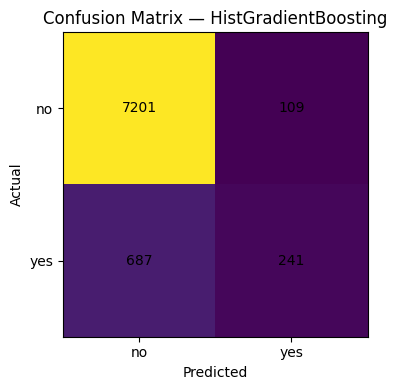

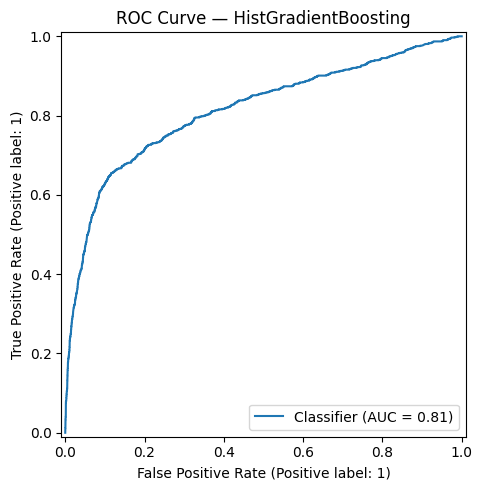

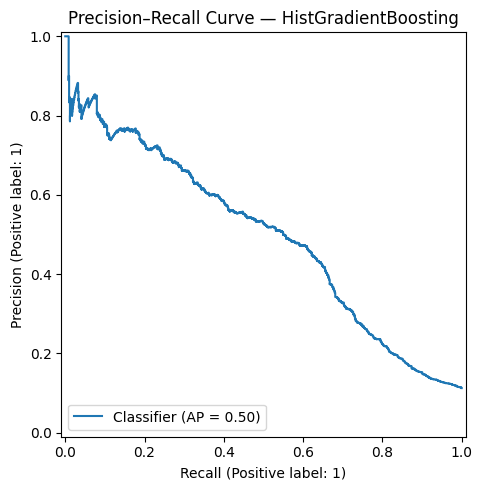

In [14]:
best_model_name = comparison.index[0]
best_model = fitted_models[best_model_name]
best_pred = best_model.predict(X_test)
best_prob = best_model.predict_proba(X_test)[:, 1]

print("Candidate selected by PR-AUC:", best_model_name)
print("\\nClassification report at threshold 0.50:")
print(classification_report(y_test, best_pred, target_names=["no", "yes"], zero_division=0))

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ["no", "yes"])
plt.yticks([0, 1], ["no", "yes"])
for (i, j), value in np.ndenumerate(cm):
    plt.text(j, i, str(value), ha="center", va="center")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, best_prob, ax=ax)
ax.set_title(f"ROC Curve — {best_model_name}")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y_test, best_prob, ax=ax)
ax.set_title(f"Precision–Recall Curve — {best_model_name}")
plt.tight_layout()
plt.show()

## 8. Threshold analysis for campaign capacity

A probability threshold of 0.50 is not automatically the best business threshold. The next table evaluates several thresholds. A lower threshold generally captures more potential subscribers (higher recall) but may also increase false positives and contact costs.

The marketing team should choose a threshold aligned with campaign budget, call-center capacity, and the relative cost of missed subscribers versus unnecessary calls.

In [15]:
threshold_rows = []
for threshold in np.arange(0.10, 0.91, 0.10):
    pred_t = (best_prob >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(y_test, pred_t, zero_division=0),
        "Recall": recall_score(y_test, pred_t, zero_division=0),
        "F1": f1_score(y_test, pred_t, zero_division=0),
        "Customers flagged": int(pred_t.sum())
    })
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(4))

,Threshold,Precision,Recall,F1,Customers flagged
0,0.1,0.3517,0.6810,0.4639,1797
1,0.2,0.4731,0.5981,0.5283,1173
2,0.3,0.5158,0.5291,0.5223,952
3,0.4,0.6204,0.3416,0.4406,511
4,0.5,0.6886,0.2597,0.3772,350
5,0.6,0.7633,0.1703,0.2784,207
6,0.7,0.7742,0.1034,0.1825,124
7,0.8,0.8413,0.0571,0.1070,63
8,0.9,1.0000,0.0011,0.0022,1


## 9. Marketing recommendations

Based on the project context and the patterns observed in the EDA/modeling outputs, the bank can consider the following actions. These are hypotheses to validate through controlled campaigns, not claims of causality.

1. **Prioritize customers by predicted probability.** Rank customers and contact the highest-scoring segment first, then adjust the cutoff to call-center capacity.
2. **Use previous campaign outcomes.** Treat prior successful contact outcomes as a potentially useful signal; test tailored follow-up strategies for clients with previous success versus failure/non-contact.
3. **Review contact frequency.** The `campaign` feature represents contacts during the current campaign. Test frequency caps and avoid repeatedly contacting low-propensity clients.
4. **Personalize outreach.** Evaluate response rates by job, education, marital status, and contact channel; use these only to support relevant offers, not to exclude customers unfairly.
5. **Experiment with timing and channel.** Compare campaign month, day, and communication type using randomized A/B tests where feasible.
6. **Track business outcomes.** Monitor subscription rate, cost per subscription, complaints/opt-outs, and incremental lift—not just model scores.
7. **Respect customer consent and privacy.** Use customer information only for permitted purposes and provide appropriate opt-out mechanisms.

## 10. Challenges faced and techniques used

| Challenge | Technique used | Reason |
|---|---|---|
| Imbalanced target (`yes` is much less common) | Stratified split; precision, recall, F1, ROC-AUC and PR-AUC | Maintains class ratio and avoids relying on accuracy alone |
| `duration` creates leakage | Excluded from predictive inputs | Duration is known only after the call |
| Categorical variables with many levels | One-hot encoding with `handle_unknown='ignore'` | Allows categorical features and handles unseen categories at inference |
| Unknown / missing categorical values | Keep `unknown` as a category; pipeline imputation for nulls | Avoids discarding potentially informative records |
| Different numeric scales | Standardization in preprocessing pipeline | Helps scale-sensitive Logistic Regression |
| Risk of train/test contamination | Fit preprocessing within a pipeline on training data | Test data remains unseen during preprocessing |
| Nonlinear customer behavior | Compare Logistic Regression, Random Forest, and boosting | Different model families capture different patterns |
| Business threshold differs from 0.50 | Threshold analysis | Allows trade-off based on contact capacity and campaign cost |
| Historical dataset may not reflect current behavior | Recommend time-based validation and ongoing monitoring | Campaign response can change over time |

## 11. Model comparison report and production recommendation

The comparison table above provides the measured performance of each candidate on the held-out test set. The initial candidate is the model with the highest PR-AUC, but it should not be promoted automatically.

**Production recommendation:** Begin with the highest-PR-AUC model as a challenger/candidate. Before deployment:
- validate on a later time period (temporal holdout) to test future campaign performance;
- inspect probability calibration;
- select the decision threshold based on campaign capacity and costs;
- review fairness, privacy, consent, and business constraints;
- monitor precision, recall, subscription rate, and drift after deployment.

For a transparent baseline, Logistic Regression may be preferred if its performance is close to the strongest nonlinear model. If the nonlinear model provides a meaningful improvement in PR-AUC and business lift, it may be preferable subject to monitoring and governance.

## 12. Conclusion

This project analyzed the Portuguese bank's direct-marketing dataset and built classification models to estimate term-deposit subscription. The workflow uses a leakage-aware feature set, appropriate preprocessing, stratified evaluation, and metrics suited to an imbalanced target. Model comparison and threshold analysis provide a basis for prioritizing customer outreach. The final model and cutoff should be validated on newer campaign data and judged by measurable business impact, not accuracy alone.